# Renewable generation investigation

**Student:** Matilda Alford (ALFO0043)

Investigate renewable generation forecasting using Random Forest and gradient boosting, then assess renewable contribution against electricity demand. The selected model will later be integrated into `models/RenewableModel.py`.

This notebook starts from the cleaned hourly NSW dataset. It reuses the shared feature transformations without trimming to curtailment coverage, and excludes all curtailment features. The shared pipeline and its datasets remain unchanged.


In [9]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Support launching from the repository root, A2, or A2/notebooks.
a2_candidates = [Path.cwd(), Path.cwd() / "A2", Path.cwd().parent]
A2_DIR = next(
    (p.resolve() for p in a2_candidates
     if (p / "A1_data_pipeline" / "helper_functions.py").is_file()),
    None,
)
if A2_DIR is None:
    raise FileNotFoundError("Launch this notebook from the repository root, A2, or A2/notebooks.")
if str(A2_DIR) not in sys.path:
    sys.path.insert(0, str(A2_DIR))

from A1_data_pipeline.helper_functions import (
    drop_redundant_columns,
    fill_short_gaps,
    add_time_features,
    add_lag_features,
)


## Load the cleaned data

The cleaned dataset retains the earlier history removed by the shared curtailment coverage trim. Check timestamps before using row shifts as hourly lags.


In [10]:
DATA_PATH = A2_DIR / "data" / "processed" / "electricity_cleaned.parquet"
cleaned = pd.read_parquet(DATA_PATH).sort_values("timestamp").reset_index(drop=True)

if not isinstance(cleaned["timestamp"].dtype, pd.DatetimeTZDtype):
    raise ValueError("Expected timezone-aware timestamps.")
if cleaned["timestamp"].isna().any() or cleaned["timestamp"].duplicated().any():
    raise ValueError("Investigate missing or duplicate timestamps before creating features.")
if not cleaned["timestamp"].diff().dropna().eq(pd.Timedelta(hours=1)).all():
    raise ValueError("Expected a continuous hourly timeline.")

print(f"Cleaned data: {len(cleaned):,} rows")
print(f"Period: {cleaned.timestamp.min()} to {cleaned.timestamp.max()}")
display(cleaned.head())


Cleaned data: 58,992 rows
Period: 2020-01-01 00:00:00+10:00 to 2026-09-23 23:00:00+10:00


,timestamp,curtailment,curtailment_energy,curtailment_solar_utility,curtailment_solar_utility_energy,curtailment_wind,curtailment_wind_energy,demand,demand_energy,demand_gross,...,generation_renewable_with_storage,generation_renewable_with_storage_energy,price,renewable_proportion,renewable_with_storage_proportion,emissions,energy,market_value,power,storage_battery
0,2020-01-01 00:00:00+10:00,0.0,0.0,0.0,0.0,0.0,0.0,7052.475000,7067.9512,7158.123133,...,808.773125,810.4214,50.152131,11.30,11.30,6645.0214,8083.6755,405474.2070,8083.675475,NaN
1,2020-01-01 01:00:00+10:00,0.0,0.0,0.0,0.0,0.0,0.0,6595.704167,6615.1474,6676.796617,...,602.624967,609.2567,49.833788,9.03,9.03,6395.2204,7602.1548,378790.8041,7602.154583,NaN
2,2020-01-01 02:00:00+10:00,0.0,0.0,0.0,0.0,0.0,0.0,6251.667500,6262.0709,6327.247625,...,528.989308,530.5043,48.859779,8.36,8.36,6086.2442,7181.1543,350894.3070,7181.154642,NaN
3,2020-01-01 03:00:00+10:00,0.0,0.0,0.0,0.0,0.0,0.0,6083.255000,6088.7196,6159.452158,...,470.150900,472.2573,49.357085,7.63,7.63,6011.2784,7038.1160,347407.3325,7038.114875,NaN
4,2020-01-01 04:00:00+10:00,0.0,0.0,0.0,0.0,0.0,0.0,6051.651667,6053.2087,6118.741817,...,449.863725,450.4967,48.955698,7.35,7.35,5788.9150,6769.6204,331433.1931,6769.621333,NaN


## Prepare features without curtailment

Drop all curtailment columns before applying the remaining shared transformations. Keep short-gap imputation flags, calendar features, and historical price, demand and renewable generation features. The initial 168 hours are still removed because weekly lags require that history.

The shared gap helper interpolates between surrounding observations. This is useful for exploration, but uses a later observation to fill a gap. Before forecasting evaluation, decide on a past-only missing-data policy or exclude affected samples and their dependent features. Feature selection and forecast horizon are also still to be decided.


In [11]:
curtailment_columns = [c for c in cleaned.columns if c.startswith("curtailment")]
renewable_data = cleaned.drop(columns=curtailment_columns).copy()
renewable_data, redundant_columns = drop_redundant_columns(renewable_data)
renewable_data, filled_counts, unfilled_counts = fill_short_gaps(renewable_data, max_gap_hours=3)
renewable_data, time_columns = add_time_features(renewable_data)
renewable_data, lag_columns, warmup_rows = add_lag_features(
    renewable_data,
    columns=["price", "demand", "generation_renewable"],
    lag_hours=[1, 24, 168],
    rolling_hours=24,
)
renewable_data = renewable_data.set_index("timestamp").sort_index()

assert not any(c.startswith("curtailment") for c in renewable_data.columns)
print(f"Removed curtailment columns: {curtailment_columns}")
print(f"Lag warm-up: {warmup_rows} hours")
print(f"Prepared data: {len(renewable_data):,} rows, {len(renewable_data.columns)} columns")
print(f"Period: {renewable_data.index.min()} to {renewable_data.index.max()}")
print(f"Short gaps filled: {filled_counts}")
print(f"Remaining gaps: {unfilled_counts}")
display(renewable_data.head())


Removed curtailment columns: ['curtailment', 'curtailment_energy', 'curtailment_solar_utility', 'curtailment_solar_utility_energy', 'curtailment_wind', 'curtailment_wind_energy']
Lag warm-up: 168 hours
Prepared data: 58,824 rows, 34 columns
Period: 2020-01-08 00:00:00+10:00 to 2026-09-23 23:00:00+10:00
Short gaps filled: {'flow_exports': 4, 'flow_imports': 4}
Remaining gaps: {'flow_exports': 0, 'flow_imports': 0}


,demand,demand_gross,flow_exports,flow_imports,generation_renewable,generation_renewable_with_storage,price,renewable_proportion,renewable_with_storage_proportion,emissions,...,demand_lag_1h,demand_lag_24h,demand_lag_168h,demand_rolling_mean_24h,demand_rolling_std_24h,generation_renewable_lag_1h,generation_renewable_lag_24h,generation_renewable_lag_168h,generation_renewable_rolling_mean_24h,generation_renewable_rolling_std_24h
timestamp,,,,,,,,,,,,,,,,,,,,,
2020-01-08 00:00:00+10:00,7197.789167,7329.212283,117.327377,96.735801,541.021733,541.021733,52.723042,7.38,7.38,6053.7531,...,7461.300000,6928.290833,7052.475000,8244.178333,1290.593657,650.174417,884.034783,808.773125,1277.037450,670.526262
2020-01-08 01:00:00+10:00,6746.405833,6854.707617,2.708954,332.532460,453.366467,453.366467,47.943420,6.61,6.61,5520.3605,...,7197.789167,6458.664167,6595.704167,8255.407431,1279.773754,541.021733,842.003017,602.624967,1262.745240,682.810413
2020-01-08 02:00:00+10:00,6527.559167,6625.711133,0.000000,522.268398,405.790692,405.790692,41.571833,6.12,6.12,5237.9776,...,6746.405833,6227.864167,6251.667500,8267.396667,1263.453334,453.366467,853.877917,528.989308,1246.552050,697.669041
2020-01-08 03:00:00+10:00,6467.107500,6558.768200,0.000000,615.929918,350.059742,350.059742,43.932137,5.34,5.34,5313.7468,...,6527.559167,6241.953333,6083.255000,8279.883958,1243.746598,405.790692,800.649800,470.150900,1227.881749,714.428591
2020-01-08 04:00:00+10:00,6677.536667,6765.598083,0.000000,517.602041,338.105717,338.105717,45.483957,5.00,5.00,5567.7862,...,6467.107500,6463.109167,6051.651667,8289.265382,1228.461636,350.059742,738.465167,449.863725,1209.107163,731.852134


## Initial data checks

`generation_renewable` is the proposed regression target. Demand will provide context for assessing renewable contribution. Other retained measurements are candidates for exploration, rather than an agreed model input list: features must be available at forecast time, and target-derived columns can leak the answer when predicting the same hour.


,generation_renewable,demand,renewable_proportion
count,58824.000000,58824.000000,58824.000000
mean,2467.832146,7567.239018,27.233821
std,1978.060802,1363.576438,18.894541
min,24.417750,2577.155833,0.280000
25%,1011.705136,6630.016250,12.980000
50%,1689.983733,7435.197500,20.600000
75%,3506.471346,8340.218959,38.240000
max,10898.422467,13641.368333,96.250000


,missing_count


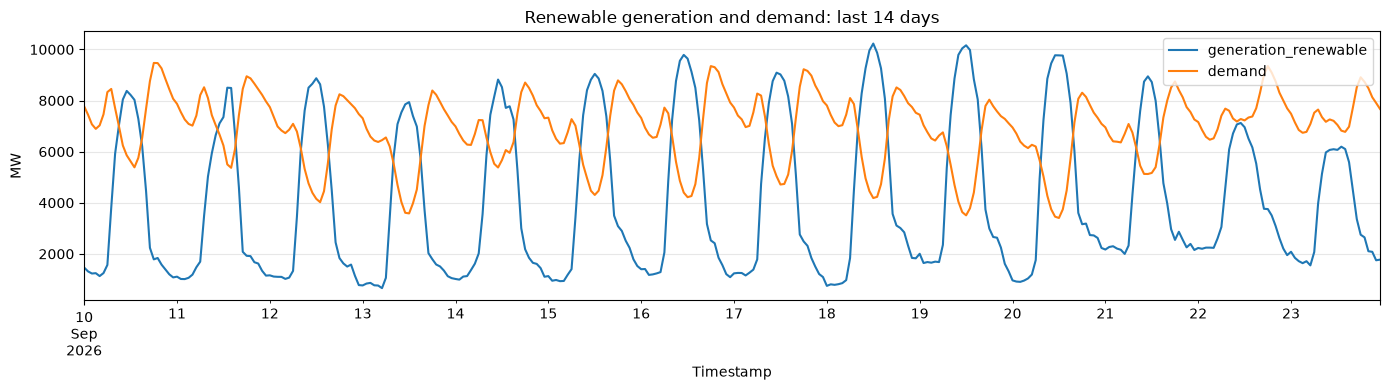

In [12]:
display(renewable_data[["generation_renewable", "demand", "renewable_proportion"]].describe())
missing = renewable_data.isna().sum()
display(missing[missing.gt(0)].rename("missing_count").to_frame())

fig, ax = plt.subplots(figsize=(14, 4))
renewable_data[["generation_renewable", "demand"]].iloc[-24 * 14:].plot(ax=ax)
ax.set(title="Renewable generation and demand: last 14 days", ylabel="MW", xlabel="Timestamp")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## First experiment: next-hour renewable generation

At the end of hour **t**, predict `generation_renewable` for **t + 1 hour**, in MW. This matches the current demand model's next-hour horizon; a 24-hour forecast will require a separate experiment.

Use measured renewable generation and demand up to t, their historical summaries, and calendar features for the forecast hour. This assumes the measurements at t have been published; actual publication delays must be accounted for in live integration. Exclude price, imports/exports, renewable proportions and other contemporaneous measurements for this first comparison. No feature scaling is required for these tree models.

Rebuild these features from the **unimputed cleaned measurements**. This avoids using the shared helper's two-sided interpolation in forecasting evaluation. Missing predictor or target rows are dropped after feature construction, without collapsing the hourly timeline before shifts. This keeps the earlier transformation available for exploration while making the modelling inputs independent of interpolated values.

In [13]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

HORIZON_HOURS = 1
RANDOM_STATE = 42

history = cleaned.set_index("timestamp").sort_index()
features = pd.DataFrame(index=history.index)
for column in ["generation_renewable", "demand"]:
    features[column] = history[column]
    for lag in [1, 24, 168]:
        features[f"{column}_lag_{lag}h"] = history[column].shift(lag)
    # These windows include hour t, which is observed at this forecast origin.
    features[f"{column}_mean_24h"] = history[column].rolling(24).mean()
    features[f"{column}_std_24h"] = history[column].rolling(24).std()
    features[f"{column}_change_1h"] = history[column].diff()

# Known calendar information for the hour being predicted, in NSW local time.
forecast_times = features.index + pd.Timedelta(hours=HORIZON_HOURS)
local_target = forecast_times.tz_convert("Australia/Sydney")
for name, values, period in [
    ("target_hour", local_target.hour, 24),
    ("target_weekday", local_target.dayofweek, 7),
    ("target_month", local_target.month - 1, 12),
]:
    features[f"{name}_sin"] = np.sin(2 * np.pi * values / period)
    features[f"{name}_cos"] = np.cos(2 * np.pi * values / period)
features["target_is_weekend"] = (local_target.dayofweek >= 5).astype(int)

FEATURE_COLUMNS = features.columns.tolist()
experiment = features.copy()
experiment["target"] = history["generation_renewable"].shift(-HORIZON_HOURS)
experiment["forecast_time"] = forecast_times
experiment["persistence"] = history["generation_renewable"]
# At t, the observation for the forecast hour minus 24h is t - 23h.
experiment["daily_seasonal"] = history["generation_renewable"].shift(24 - HORIZON_HOURS)
rows_before_drop = len(experiment)
experiment = experiment.replace([np.inf, -np.inf], np.nan).dropna()

print(f"Forecast horizon: {HORIZON_HOURS} hour")
print(f"Predictors: {len(FEATURE_COLUMNS)}")
print(f"Usable examples: {len(experiment):,}; removed: {rows_before_drop - len(experiment):,}")
display(experiment[["forecast_time", "generation_renewable", "target", "daily_seasonal"]].head())

Forecast horizon: 1 hour
Predictors: 21
Usable examples: 58,823; removed: 169


,forecast_time,generation_renewable,target,daily_seasonal
timestamp,,,,
2020-01-08 00:00:00+10:00,2020-01-08 01:00:00+10:00,541.021733,453.366467,842.003017
2020-01-08 01:00:00+10:00,2020-01-08 02:00:00+10:00,453.366467,405.790692,853.877917
2020-01-08 02:00:00+10:00,2020-01-08 03:00:00+10:00,405.790692,350.059742,800.649800
2020-01-08 03:00:00+10:00,2020-01-08 04:00:00+10:00,350.059742,338.105717,738.465167
2020-01-08 04:00:00+10:00,2020-01-08 05:00:00+10:00,338.105717,240.496508,762.738158


## Chronological evaluation

Use target timestamps to define the splits: training before 24 September 2024, validation for the following year, and a final test from 24 September 2025. Boundaries use fixed AEST, matching the stored timeline. Historical observations before a boundary may supply lags for the next split, as they would in operation.

Choose the ML algorithm using validation MAE only. Refit that algorithm on training plus validation, then evaluate once on the held-out test year. Models remain fixed within each evaluation period; each prediction uses the latest observed history. This is a sequence of one-hour forecasts, not a year-long forecast issued at once. These are initial settings, not a completed hyperparameter search.

In [14]:
VALIDATION_START = pd.Timestamp("2024-09-24", tz=history.index.tz)
TEST_START = pd.Timestamp("2025-09-24", tz=history.index.tz)

train = experiment.loc[experiment.forecast_time < VALIDATION_START].copy()
validation = experiment.loc[
    (experiment.forecast_time >= VALIDATION_START)
    & (experiment.forecast_time < TEST_START)
].copy()
test = experiment.loc[experiment.forecast_time >= TEST_START].copy()

if any(part.empty for part in [train, validation, test]):
    raise ValueError("Each chronological split must contain examples.")
assert train.forecast_time.max() < validation.forecast_time.min()
assert validation.forecast_time.max() < test.forecast_time.min()

split_summary = pd.DataFrame([
    {"split": name, "rows": len(part), "first_target": part.forecast_time.min(),
     "last_target": part.forecast_time.max()}
    for name, part in [("train", train), ("validation", validation), ("test", test)]
]).set_index("split")
display(split_summary)

candidates = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=20, min_samples_leaf=4,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=2,
    ),
    "Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=200, learning_rate=0.05, max_leaf_nodes=31,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=RANDOM_STATE,
    ),
}

def forecast_metrics(actual, predicted):
    return {
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted),
        "Bias (MW)": np.mean(np.asarray(predicted) - np.asarray(actual)),
    }

validation_predictions = validation[["persistence", "daily_seasonal"]].rename(
    columns={"persistence": "Persistence", "daily_seasonal": "Daily seasonal"}
)
for name, estimator in candidates.items():
    estimator.fit(train[FEATURE_COLUMNS], train["target"])
    validation_predictions[name] = estimator.predict(validation[FEATURE_COLUMNS])

validation_scores = pd.DataFrame({
    name: forecast_metrics(validation["target"], validation_predictions[name])
    for name in validation_predictions
}).T
validation_scores["MAE improvement vs persistence (%)"] = (
    100 * (1 - validation_scores["MAE (MW)"] / validation_scores.loc["Persistence", "MAE (MW)"])
)
display(validation_scores.sort_values("MAE (MW)").round(3))
selected_name = validation_scores.loc[list(candidates), "MAE (MW)"].idxmin()
print(f"Selected ML algorithm by validation MAE: {selected_name}")
print("Positive bias means overprediction; negative bias means underprediction.")

,rows,first_target,last_target
split,,,
train,41303,2020-01-08 01:00:00+10:00,2024-09-23 23:00:00+10:00
validation,8760,2024-09-24 00:00:00+10:00,2025-09-23 23:00:00+10:00
test,8760,2025-09-24 00:00:00+10:00,2026-09-23 23:00:00+10:00


,MAE (MW),RMSE (MW),R²,Bias (MW),MAE improvement vs persistence (%)
Gradient Boosting,214.847,318.070,0.981,-39.986,57.149
Random Forest,221.119,325.410,0.980,-46.775,55.898
Persistence,501.384,770.532,0.889,-0.075,0.000
Daily seasonal,631.178,867.470,0.860,-0.293,-25.887


Selected ML algorithm by validation MAE: Gradient Boosting
Positive bias means overprediction; negative bias means underprediction.


## Final holdout and error inspection

The test results below measure the selected configuration after refitting on all pre-test examples. Keep this test set out of tuning decisions; use validation or time-series cross-validation for subsequent experiments. Persistence is a particularly useful benchmark for next-hour generation, where the latest measurement can be highly informative.

,MAE (MW),RMSE (MW),R²,Bias (MW),MAE improvement vs persistence (%)
Gradient Boosting,235.719,338.079,0.984,-47.448,58.661
Persistence,570.208,865.823,0.893,-0.090,0.000
Daily seasonal,674.217,938.336,0.875,-1.236,-18.241


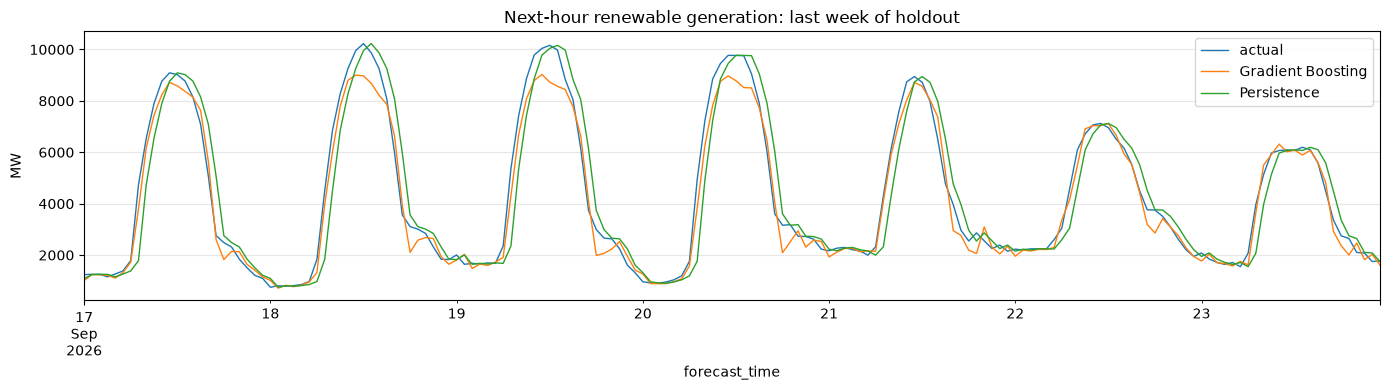

,MAE_MW,bias_MW,count
hour,,,
0,105.56,8.94,365
1,86.66,23.02,365
2,85.59,14.54,365
3,70.89,-2.30,365
4,75.67,-8.71,365
5,89.86,-5.70,365
6,166.62,-47.86,365
7,375.76,-113.89,365
8,424.11,-262.92,365


In [15]:
development = pd.concat([train, validation]).sort_index()
final_model = clone(candidates[selected_name])
final_model.fit(development[FEATURE_COLUMNS], development["target"])

holdout = pd.DataFrame({
    "actual": test["target"].to_numpy(),
    "Persistence": test["persistence"].to_numpy(),
    "Daily seasonal": test["daily_seasonal"].to_numpy(),
    selected_name: final_model.predict(test[FEATURE_COLUMNS]),
}, index=pd.DatetimeIndex(test["forecast_time"], name="forecast_time"))

test_scores = pd.DataFrame({
    name: forecast_metrics(holdout["actual"], holdout[name])
    for name in ["Persistence", "Daily seasonal", selected_name]
}).T
test_scores["MAE improvement vs persistence (%)"] = (
    100 * (1 - test_scores["MAE (MW)"] / test_scores.loc["Persistence", "MAE (MW)"])
)
display(test_scores.sort_values("MAE (MW)").round(3))

recent = holdout.iloc[-24 * 7:]
fig, ax = plt.subplots(figsize=(14, 4))
recent[["actual", selected_name, "Persistence"]].plot(ax=ax, linewidth=1)
ax.set(title="Next-hour renewable generation: last week of holdout", ylabel="MW")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

errors = holdout[selected_name] - holdout["actual"]
hourly_errors = pd.DataFrame({
    "hour": holdout.index.tz_convert("Australia/Sydney").hour,
    "absolute_error": errors.abs().to_numpy(),
    "error": errors.to_numpy(),
}).groupby("hour").agg(
    MAE_MW=("absolute_error", "mean"), bias_MW=("error", "mean"), count=("error", "size")
)
display(hourly_errors.round(2))

## Initial findings

With the fixed settings above, validation MAE is **214.85 MW for gradient boosting** and **221.12 MW for Random Forest**, compared with **501.38 MW for persistence**. Gradient boosting is therefore selected for the holdout evaluation.

After refitting on training plus validation, gradient boosting achieves **235.72 MW test MAE**, versus **570.21 MW for persistence** and **674.22 MW for the daily seasonal baseline**: a **58.66% reduction in MAE relative to persistence**. These findings apply to hourly NSW renewable generation and this one-hour forecast setup; they do not establish performance for a 24-hour horizon.

The hourly error table shows larger errors during daytime, particularly around the morning ramp. This suggests a useful area for follow-up evaluation on pre-test data. The current model remains an initial forecasting result; the standalone symbolic assessment is developed below; Oli will handle combined model integration separately.

These figures describe the saved run and should be updated if the experiment changes.

## Pre-test tuning with time-series cross-validation

Compare a small, explicit set of settings across three expanding-window folds. Each validation fold spans 90 days; the folds occupy the last 270 days of the development period. Training always precedes the forecast targets being scored. Each fold contains a complete set of one-hour-ahead predictions using observed history, with no recursive forecast inputs.

Use the **mean fold MAE** to rank configurations, and report the fold-to-fold standard deviation. This is a limited search rather than evidence of optimal settings. Random Forest uses 100 trees here to keep the comparison practical; depth and leaf size explore different levels of regularisation. Histogram gradient boosting is the scikit-learn gradient boosting implementation used throughout this notebook.

The original test results above are retained as the initial experiment's benchmark. These follow-up experiments use only pre-test examples, but the test has already been viewed: a newly tuned model will need fresh future data for a new independent performance claim. Do not rerank the tuned configurations using the existing test year.

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
from time import perf_counter

# Build development data explicitly from pre-test targets.
cv_data = experiment.loc[experiment.forecast_time < TEST_START].copy()
cv_splitter = TimeSeriesSplit(n_splits=3, test_size=24 * 90)
cv_folds = list(cv_splitter.split(cv_data))

search_models = {
    "RF: depth 20, leaf 4": RandomForestRegressor(
        n_estimators=100, max_depth=20, min_samples_leaf=4,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=2,
    ),
    "RF: depth 16, leaf 12": RandomForestRegressor(
        n_estimators=100, max_depth=16, min_samples_leaf=12,
        max_features=0.8, random_state=RANDOM_STATE, n_jobs=2,
    ),
    "GB: 200 iterations, 31 leaves": clone(candidates["Gradient Boosting"]),
    "GB: 300 iterations, 15 leaves": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=RANDOM_STATE,
    ),
    "GB: 300 iterations, 31 leaves": HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
        min_samples_leaf=20, l2_regularization=1.0,
        early_stopping=False, random_state=RANDOM_STATE,
    ),
}

fold_details = []
cv_records = []
last_fold_models = {}
# Limit native numerical threads as well as Random Forest's worker count.
with threadpool_limits(limits=2):
    for fold, (fit_indices, score_indices) in enumerate(cv_folds, start=1):
        fit_data = cv_data.iloc[fit_indices]
        score_data = cv_data.iloc[score_indices]
        assert fit_data.forecast_time.max() < score_data.forecast_time.min()
        assert score_data.forecast_time.max() < TEST_START
        fold_details.append({
            "fold": fold, "training_rows": len(fit_data),
            "training_end": fit_data.forecast_time.max(),
            "validation_start": score_data.forecast_time.min(),
            "validation_end": score_data.forecast_time.max(),
        })
        for name, column in [("Persistence", "persistence"), ("Daily seasonal", "daily_seasonal")]:
            cv_records.append({
                "configuration": name, "fold": fold,
                **forecast_metrics(score_data["target"], score_data[column]),
                "fit_seconds": 0.0,
            })
        for name, prototype in search_models.items():
            started = perf_counter()
            fitted = clone(prototype).fit(fit_data[FEATURE_COLUMNS], fit_data["target"])
            fit_seconds = perf_counter() - started
            predictions = fitted.predict(score_data[FEATURE_COLUMNS])
            cv_records.append({
                "configuration": name, "fold": fold,
                **forecast_metrics(score_data["target"], predictions),
                "fit_seconds": fit_seconds,
            })
            if fold == len(cv_folds):
                last_fold_models[name] = fitted
        print(f"Completed fold {fold}/{len(cv_folds)}")

cv_results = pd.DataFrame(cv_records)
cv_summary = cv_results.groupby("configuration").agg(
    mean_MAE_MW=("MAE (MW)", "mean"),
    std_MAE_MW=("MAE (MW)", "std"),
    mean_RMSE_MW=("RMSE (MW)", "mean"),
    mean_bias_MW=("Bias (MW)", "mean"),
    mean_fit_seconds=("fit_seconds", "mean"),
).sort_values("mean_MAE_MW")
cv_summary["MAE_improvement_vs_persistence_pct"] = 100 * (
    1 - cv_summary.mean_MAE_MW / cv_summary.loc["Persistence", "mean_MAE_MW"]
)
cv_selected_name = cv_summary.loc[list(search_models), "mean_MAE_MW"].idxmin()
display(pd.DataFrame(fold_details).set_index("fold"))
display(cv_summary.round(3))
display(cv_results.pivot(index="configuration", columns="fold", values="MAE (MW)").round(2))
print(f"Selected configuration by mean pre-test CV MAE: {cv_selected_name}")
if cv_summary.loc[cv_selected_name, "mean_MAE_MW"] >= cv_summary.loc["Persistence", "mean_MAE_MW"]:
    print("The selected ML model did not beat persistence in this comparison.")

Completed fold 1/3


## What does the selected model use?

Permutation importance measures how much MAE increases when one predictor is shuffled. Evaluate on the final cross-validation fold using the model trained **before** that fold, never the model refitted on all development data. Positive values indicate a useful predictor in this context; near-zero or negative values may reflect noise or redundant information.

Renewable measurements and their lags are correlated, so they can substitute for one another. Individual importance values are predictive diagnostics, not causal effects or a definitive reason to remove a feature. Randomly shuffling time-series features can also create unrealistic combinations. Use this analysis to guide further pre-test investigation.

Refitted GB: 300 iterations, 31 leaves on 50,063 pre-test examples.
tuned_model is in memory only; no model artifact has been saved.


,MAE_increase_MW,repeat_std_MW
feature,,
generation_renewable,1812.018,10.375
generation_renewable_change_1h,215.529,5.317
target_hour_cos,134.564,1.886
target_hour_sin,71.543,5.145
demand_change_1h,38.320,4.097
generation_renewable_mean_24h,9.164,0.797
generation_renewable_lag_24h,7.432,0.676
demand_lag_24h,4.734,0.557
generation_renewable_std_24h,4.604,0.617


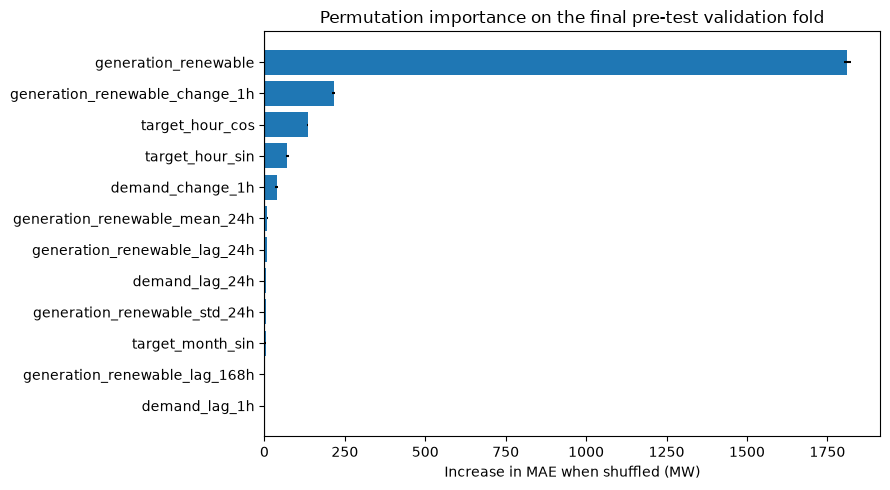

In [ ]:
importance_data = cv_data.iloc[cv_folds[-1][1]]
with threadpool_limits(limits=2):
    importance_result = permutation_importance(
        last_fold_models[cv_selected_name],
        importance_data[FEATURE_COLUMNS], importance_data["target"],
        scoring="neg_mean_absolute_error", n_repeats=3,
        random_state=RANDOM_STATE, n_jobs=1,
    )
importance_table = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "MAE_increase_MW": importance_result.importances_mean,
    "repeat_std_MW": importance_result.importances_std,
}).sort_values("MAE_increase_MW", ascending=False).set_index("feature")
display(importance_table.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
top_features = importance_table.head(12).sort_values("MAE_increase_MW")
ax.barh(top_features.index, top_features.MAE_increase_MW, xerr=top_features.repeat_std_MW)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Permutation importance on the final pre-test validation fold",
       xlabel="Increase in MAE when shuffled (MW)")
plt.tight_layout()
plt.show()

# Prepare the CV-selected candidate for later integration; do not score it on
# the already viewed test year, and do not overwrite the initial final_model.
with threadpool_limits(limits=2):
    tuned_model = clone(search_models[cv_selected_name]).fit(
        cv_data[FEATURE_COLUMNS], cv_data["target"]
    )
print(f"Refitted {cv_selected_name} on {len(cv_data):,} pre-test examples.")
print("tuned_model is in memory only; no model artifact has been saved.")

## Cross-validation findings

The best configuration in this small search is **gradient boosting with 300 iterations and 31 leaves**. It has the lowest MAE in all three folds and a mean MAE of **187.31 MW**, compared with **200.51 MW** for the best Random Forest and **489.45 MW** for persistence. This is a **61.73% reduction relative to persistence on these validation folds**. The 200-iteration gradient boosting configuration averages **190.08 MW**, so the extra iterations provide a modest improvement rather than a large change.

Permutation importance on the last validation fold indicates that current renewable generation, its one-hour change, and the forecast hour are especially useful. Demand's recent change also contributes. These are predictive associations, subject to the correlation and shuffling limitations noted above.

`tuned_model` is refitted on the 50,063 pre-test examples using the CV-selected settings. **187.31 MW is a cross-validation selection score, not a new independent test score.** The initial model's separate test MAE remains 235.72 MW. The selected tuned model is ready for the next integration step, with NPZ export and renewable sufficiency rules below.

These figures describe the saved run and should be updated when the experiment changes.

## Follow-up investigation and integration

- Review the CV comparison and feature importance. Use pre-test data for any further feature or hyperparameter changes, and collect fresh future data for an independent assessment of the tuned model.
- Align one-hour renewable forecasts with Oli's demand forecasts by target timestamp. Evaluate renewable contribution or a chosen renewable-share goal; renewable generation below total demand does not by itself mean total supply is insufficient.
- The symbolic section below applies miniKanren rules with a default 50% hourly coverage target and 40% / 82% scenarios.
- Once the forecasting design is agreed, save the model together with feature definitions, feature order and metadata, and implement the same transformations in `RenewableModel.py`.

`final_model` is the original holdout-tested model, and `tuned_model` is selected using pre-test cross-validation. Both are retained separately in notebook memory. The export section below saves the CV-selected model as an NPZ artifact.

## Save the selected model as NPZ and verify inference

Export the fitted `tuned_model` together with its feature order, hyperparameters, forecast horizon and training cutoff. The fitted boosting trees must also be stored: saving constructor parameters alone would lose what the model learned. The NPZ contains a numeric byte array holding the serialized fitted estimator and readable metadata, with no object arrays. Load only your own trusted model artifacts, using the same scikit-learn version.

The archive below contains the **pre-test CV-selected model**, not a model trained on the test year. The training pipeline can later refit the chosen configuration on all cleaned history for deployment. Saving that deployment model to the same default path replaces this archive, without changing the notebook's recorded evaluation results.

The round-trip check compares predictions before and after saving and verifies that the notebook and inference code construct identical features. No model fitting happens during loading or inference.

In [10]:
from models.RenewableModel import RenewableModel

# Ensure deployment feature engineering exactly matches this investigation.
shared_features = RenewableModel.build_features(cleaned)
pd.testing.assert_frame_equal(shared_features.loc[features.index], features)
assert FEATURE_COLUMNS == RenewableModel.FEATURES

exported_model = RenewableModel(model=tuned_model)
exported_model.trained_through = cv_data["forecast_time"].max().isoformat()
exported_model.save()
with np.load(RenewableModel.DEFAULT_PATH, allow_pickle=False) as archive:
    print("NPZ entries:", archive.files)
    print("Metadata:", archive["metadata"].item())

loaded_model = RenewableModel().load()
with threadpool_limits(limits=2):
    expected = tuned_model.predict(cv_data[FEATURE_COLUMNS].tail(24))
    restored = loaded_model.model.predict(cv_data[FEATURE_COLUMNS].tail(24))
np.testing.assert_array_equal(expected, restored)

# Use raw observations through the final pre-test forecast origin.
last_origin = cv_data.index[-1]
inference_history = history.loc[:last_origin].tail(169)
round_trip_forecast = loaded_model.inference(inference_history)
assert round_trip_forecast["forecast_time"] == cv_data["forecast_time"].iloc[-1]
np.testing.assert_allclose(round_trip_forecast["generation_renewable_mw"], expected[-1])
print("Feature parity and NPZ prediction round-trip passed.")
print(f"Saved model: {RenewableModel.DEFAULT_PATH}")

NPZ entries: ['model_state', 'features', 'metadata']
Metadata: {"format_version": 1, "horizon_hours": 1, "target": "generation_renewable", "units": "MW", "calendar_timezone": "Australia/Sydney", "sklearn_version": "1.9.1", "trained_through": "2025-09-23T23:00:00+10:00", "parameters": {"categorical_features": "from_dtype", "early_stopping": false, "interaction_cst": null, "l2_regularization": 1.0, "learning_rate": 0.05, "loss": "squared_error", "max_bins": 255, "max_depth": null, "max_features": 1.0, "max_iter": 300, "max_leaf_nodes": 31, "min_samples_leaf": 20, "monotonic_cst": null, "n_iter_no_change": 10, "quantile": null, "random_state": 42, "scoring": "loss", "tol": 1e-07, "validation_fraction": 0.1, "verbose": 0, "warm_start": false}}
2025-09-23 23:00:00+10:00: renewable generation 1021 MW
Feature parity and NPZ prediction round-trip passed.
Saved model: /workspaces/COMP3742-Capstone-Project/A2/renewable_gb.npz


## Symbolic assessment: hourly renewable coverage

The default definition of **sufficient** is renewable generation covering at least **50% of forecast demand for the same hour**. This is a project-defined target, not a grid reliability criterion. Compare 40%, 50% and 82% scenarios to show how the target affects the conclusion.

The [Australian Government fuel-mix chart for calendar year 2025](https://www.energy.gov.au/energy-data/australian-energy-statistics/data-charts/australian-electricity-generation-fuel-mix-calendar-year-2025) reports NSW+ACT hydro at 3.5% and other renewables at 37.3% (40.8% combined), sourced to Australian Energy Statistics **2026**, Table O. The [Climate Change Authority](https://www.climatechangeauthority.gov.au/2025-annual-progress-report-faqs) describes the national 82% renewable electricity target for 2030. These aggregate generation-share figures provide context, not directly comparable hourly demand-coverage standards.

`RenewableRules` uses miniKanren relations and numeric goals to infer a status, rule identifier and recommendations. Forecast timestamps and one-hour horizons must match; current observed demand is never silently substituted for a forecast. These examples are illustrative inputs, not model performance measurements.

In [11]:
from prolog.RenewableRules import RenewableRules

example_time = pd.Timestamp("2026-11-03T14:00:00+10:00")
example_renewable = {"forecast_time": example_time, "horizon_hours": 1,
                     "generation_renewable_mw": 2400.0}
example_demand = {"forecast_time": example_time, "horizon_hours": 1,
                  "demand_mw": 5000.0}
scenario_rows = []
for share in [0.40, 0.50, 0.82]:
    assessment = RenewableRules(share).assess(example_renewable, example_demand)
    scenario_rows.append({key: assessment[key] for key in [
        "target_percent", "coverage_percent", "status",
        "required_renewable_mw", "renewable_shortfall_mw",
    ]})
display(pd.DataFrame(scenario_rows).set_index("target_percent"))
RenewableRules.print_assessment(RenewableRules().assess(example_renewable, example_demand))


Renewable sufficiency (2026-11-03 14:00:00+10:00): INSUFFICIENT
Forecast renewable generation 2400.0 MW covers 48.0% of forecast demand 5000.0 MW. The project target is 50% (2500.0 MW). Renewable target shortfall: 100.0 MW.
  - Review available renewable supply and renewable-charged storage before considering a response.
  - Consider shifting flexible demand to hours with higher renewable availability.
  - Check other supply and reserves separately; a renewable target shortfall alone does not imply a blackout.
Hourly renewable coverage of demand; total supply reliability is not assessed.


,coverage_percent,status,required_renewable_mw,renewable_shortfall_mw
target_percent,,,,
40.0,48.0,sufficient,2000.0,0.0
50.0,48.0,insufficient,2500.0,100.0
82.0,48.0,insufficient,4100.0,1700.0


## Sensitivity to demand uncertainty

When demand includes interval bounds, an additional rule checks whether the target holds throughout that band, fails throughout, or changes within it. Renewable generation is held fixed: this is not a joint probability or calibrated interval for renewable coverage. The point classification still uses the point demand forecast.

Here the 2,400 MW renewable forecast falls short against 5,000 MW point demand, but meets 50% of the 4,000 MW lower demand bound. The outcome therefore depends on demand within the supplied interval.

In [12]:
example_demand_with_band = {
    **example_demand, "lower_95_mw": 4000.0, "upper_95_mw": 6000.0,
}
sensitivity_example = RenewableRules().assess(example_renewable, example_demand_with_band)
assert sensitivity_example["status"] == "insufficient"
assert sensitivity_example["demand_sensitivity"] == "depends_on_demand"
RenewableRules.print_assessment(sensitivity_example)


Renewable sufficiency (2026-11-03 14:00:00+10:00): INSUFFICIENT
Forecast renewable generation 2400.0 MW covers 48.0% of forecast demand 5000.0 MW. The project target is 50% (2500.0 MW). Renewable target shortfall: 100.0 MW.
Demand sensitivity: depends_on_demand
Demand-band sensitivity holds renewable generation fixed. Renewable forecast uncertainty is not quantified.
  - Review available renewable supply and renewable-charged storage before considering a response.
  - Consider shifting flexible demand to hours with higher renewable availability.
  - Check other supply and reserves separately; a renewable target shortfall alone does not imply a blackout.
  - The target outcome changes within the demand interval; monitor the next forecast before relying on the point classification.
Hourly renewable coverage of demand; total supply reliability is not assessed.
